# Lab 7-02：Excel 分析 agent——模型看得到、算得到、畫得出，但改不到

**目標**：用 MCP server 把一份銷售 Excel 開放給本地模型，讓它用中文回答分析問題、自己畫圖。
這是課綱 Lab 7「Excel 數據自動分析智能體」的程式碼版；同一支 server 也能直接掛到 Cherry Studio 等低代碼平台（Lab 7-03）。

**你會學到**
- 怎麼設計給模型用的資料工具：結構化參數、唯讀、限制回傳列數、白名單路徑
- 小模型為什麼會亂猜工作表名稱，以及用 Resource 把「資料地圖」塞進 context 來修
- 用 pandas 算出的標準答案驗證 agent 的回答，而不是看它講得好不好聽

**前置**：Lab 7-01（`run_agent` 迴圈）；Ollama 已有 `qwen2.5:3b`。整本約 3～5 分鐘，大多花在模型推論。

**對應投影片**：「Lab7 架構」「Lab7 Server 程式」「三種原語：誰決定用」「低代碼與程式碼的邊界」

![Lab 7 Excel 分析 agent：使用者問題經 qwen2.5:3b 與 MCP Client 呼叫 excel_server 的四個工具，唯讀存取 sales.xlsx](images/excel_lab7.jpg)

*圖：主線由左到右是一次問答；server 只能讀 `sales.xlsx`，`make_chart` 另外輸出 PNG。上方黃框是 Step 7 的修法：應用程式先讀 `excel://schema` 這個 Resource，當成資料地圖交給模型。*

In [1]:
import json
import os
import sys
import time
from contextlib import asynccontextmanager
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, display
from mcp import ClientSession, StdioServerParameters
from mcp.client.stdio import stdio_client
from openai import OpenAI

from course_utils.viz import setup_cjk

setup_cjk()
XLSX = Path("data/sales.xlsx")
Path("outputs").mkdir(exist_ok=True)

## Step 1：做一份虛構的銷售報表

虛構公司「青山家電」2025 年的訂單。資料是程式生出來的，刻意埋了幾個規律讓分析有東西可看：
北區業務最多、東區最小；電風扇夏天賣、電暖器冬天賣；年底咖啡機和掃地機器人有送禮旺季。
固定亂數種子，每個人生出來的檔案內容都一樣。

In [2]:
def make_sales(path: Path, seed: int = 7) -> None:
    rng = np.random.default_rng(seed)
    products = pd.DataFrame({
        "產品": ["除濕機", "空氣清淨機", "電風扇", "電暖器", "掃地機器人", "咖啡機"],
        "類別": ["空調", "空調", "空調", "空調", "清潔", "廚房"],
        "定價": [8900, 12500, 1990, 3290, 15800, 6800],
    })
    reps = pd.DataFrame({
        "業務": ["林雅婷", "陳冠宇", "王思涵", "張家豪", "李佩珊", "黃志明", "吳欣怡", "劉俊傑"],
        "區域": ["北區", "北區", "北區", "中區", "中區", "南區", "南區", "東區"],
        "年度目標": [9_000_000, 8_000_000, 7_000_000, 6_000_000, 5_500_000, 6_500_000, 6_000_000, 3_000_000],
    })
    season = {  # 每個產品在 1～12 月的熱度
        "除濕機": [1, 1, 3, 4, 5, 4, 2, 1, 1, 1, 1, 1], "空氣清淨機": [2, 3, 4, 3, 2, 1, 1, 1, 1, 2, 3, 3],
        "電風扇": [0, 0, 1, 2, 4, 6, 6, 5, 3, 1, 0, 0], "電暖器": [5, 4, 1, 0, 0, 0, 0, 0, 0, 1, 4, 6],
        "掃地機器人": [2] * 10 + [4, 5], "咖啡機": [2] * 9 + [3, 3, 5],
    }
    region_weight = {"北區": 1.0, "中區": 0.8, "南區": 0.85, "東區": 0.4}
    rows = []
    for month in range(1, 13):
        for _, rep in reps.iterrows():
            for _ in range(rng.poisson(9 * region_weight[rep["區域"]] * (1 + 0.04 * month))):
                w = np.array([season[p][month - 1] + 0.3 for p in products["產品"]])
                p = products.iloc[rng.choice(len(products), p=w / w.sum())]
                qty = int(rng.integers(1, 6))
                price = int(p["定價"] * rng.choice([1.0, 0.95, 0.9], p=[0.6, 0.3, 0.1]))
                rows.append({"日期": pd.Timestamp(2025, month, int(rng.integers(1, 29))), "月份": f"2025-{month:02d}",
                             "區域": rep["區域"], "業務": rep["業務"], "產品": p["產品"], "類別": p["類別"],
                             "數量": qty, "單價": price, "金額": qty * price})
    orders = pd.DataFrame(rows).sort_values("日期").reset_index(drop=True)
    orders.insert(0, "訂單編號", [f"S25-{i + 1:04d}" for i in range(len(orders))])
    with pd.ExcelWriter(path) as writer:
        orders.to_excel(writer, sheet_name="訂單", index=False)
        products.to_excel(writer, sheet_name="產品", index=False)
        reps.to_excel(writer, sheet_name="業務目標", index=False)


if not XLSX.exists():  # 檔案已附在 repo 裡；刪掉它再跑就會重新生成
    make_sales(XLSX)
print(f"{XLSX}：{XLSX.stat().st_size / 1024:.0f} KB")

data/sales.xlsx：46 KB


## Step 2：先自己用 pandas 看一眼，算出標準答案

等一下 agent 會回答四個問題。先用 pandas 把答案算好，之後拿來對答案。**評估 agent 要有標準答案**，不能只看它講得順不順。

In [3]:
book = pd.read_excel(XLSX, sheet_name=None)
for name, df in book.items():
    print(f"工作表「{name}」：{df.shape[0]} 列 × {df.shape[1]} 欄 → {list(df.columns)}")
orders = book["訂單"]
orders.head(3)

工作表「訂單」：928 列 × 10 欄 → ['訂單編號', '日期', '月份', '區域', '業務', '產品', '類別', '數量', '單價', '金額']
工作表「產品」：6 列 × 3 欄 → ['產品', '類別', '定價']
工作表「業務目標」：8 列 × 3 欄 → ['業務', '區域', '年度目標']


,訂單編號,日期,月份,區域,業務,產品,類別,數量,單價,金額
0,S25-0001,2025-01-01,2025-01,北區,林雅婷,空氣清淨機,空調,5,12500,62500
1,S25-0002,2025-01-01,2025-01,北區,王思涵,電暖器,空調,5,3290,16450
2,S25-0003,2025-01-02,2025-01,中區,李佩珊,咖啡機,廚房,2,6800,13600


In [4]:
truth_region = orders.groupby("區域")["金額"].sum().sort_values(ascending=False)
truth_north = orders[orders["區域"] == "北區"].groupby("產品")["金額"].sum().sort_values(ascending=False)
truth_month = orders.groupby("月份")["金額"].sum()

print("各區域總金額：\n", truth_region.map("{:,}".format).to_string())
print("\n北區產品前三名：\n", truth_north.head(3).map("{:,}".format).to_string())
print("\n月營收最高：", truth_month.idxmax(), f"{truth_month.max():,}")

各區域總金額：
 區域
北區    9,847,613
南區    6,165,104
中區    5,485,919
東區    1,698,598

北區產品前三名：
 產品
掃地機器人    3,552,630
空氣清淨機    2,088,750
除濕機      1,853,870

月營收最高： 2025-11 2,562,628


## Step 3：server 長什麼樣——為模型設計的資料工具

打開 `servers/excel_server.py`，它只有四個工具，每個設計都有理由：

| 工具 | 做什麼 | 設計考量 |
|---|---|---|
| `list_sheets` | 列工作表與列數 | 讓模型知道有什麼 |
| `describe` | 欄位、型別、前 3 列 | 只給樣本，不給整張表 |
| `query` | 篩選 → 分組 → 彙總 → 排序 | **不收任意 pandas 程式碼**，只收結構化參數；最多回傳 20 列 |
| `make_chart` | 畫長條或折線圖，存 PNG | 只寫進 `outputs/charts/`，不碰原始檔 |

另外所有工具都只能讀 `data/` 裡的 `.xlsx`，傳 `../../.env` 之類的路徑會被擋下（Lab 7-03 示範）。

為什麼不乾脆給一個 `run_pandas(code)` 工具？因為那等於讓模型在你的機器上執行任意程式碼，
而且 3B 模型寫的 pandas 常常跑不動。結構化參數讓模型「只能問正確形狀的問題」。

In [5]:
@asynccontextmanager
async def connect(script: str):
    params = StdioServerParameters(command=sys.executable, args=[script])
    with open("outputs/server_stderr.log", "a", encoding="utf-8") as errlog:
        async with stdio_client(params, errlog=errlog) as (read, write):
            async with ClientSession(read, write) as session:
                await session.initialize()
                yield session


SERVER = "servers/excel_server.py"
async with connect(SERVER) as session:
    for tool in (await session.list_tools()).tools:
        params = list(tool.inputSchema["properties"])
        print(f"■ {tool.name}({', '.join(params)})  唯讀={tool.annotations.readOnlyHint}")

■ list_sheets(file)  唯讀=True
■ describe(sheet, file)  唯讀=True
■ query(sheet, group_by, value_column, agg, where_column, where_value, limit, file)  唯讀=True
■ make_chart(sheet, x, y, kind, agg, where_column, where_value, title, file)  唯讀=True


## Step 4：不用模型，自己按一次每個工具

先確認工具本身是對的，再交給模型。工具有 bug 時，模型只會更混亂。

{"訂單": 928, "產品": 6, "業務目標": 8}
{"rows": 8, "columns": {"業務": "str", "區域": "str", "年度目標": "int64"}, "head": [{"業務": "林雅婷", "區域": "北區", "年度目標": "9000000"}, {"業務": "陳冠宇", "區域": "北區", "年度目標": "8000000"}, {"業務": "王思涵", "區域": "北區", "年度目標": "7000000"}]}
{"rows": [{"區域": "北區", "金額_sum": "9,847,613"}, {"區域": "南區", "金額_sum": "6,165,104"}, {"區域": "中區", "金額_sum": "5,485,919"}, {"區域": "東區", "金額_sum": "1,698,598"}], "shown": 4, "total_groups": 4}


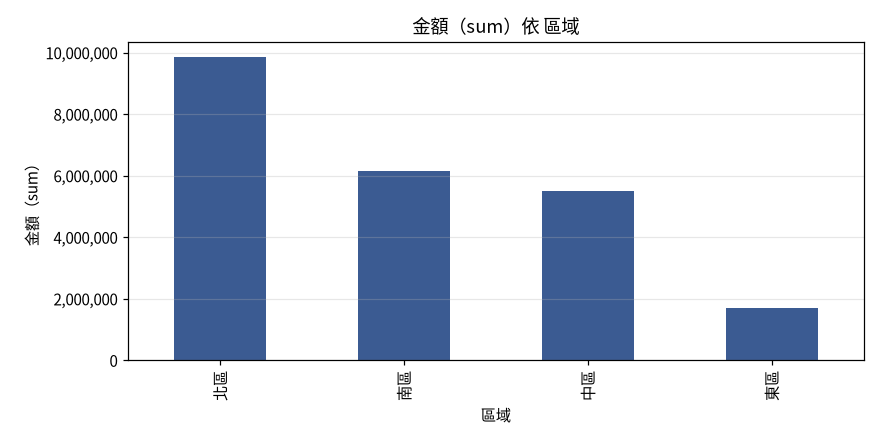

In [6]:
async def call(session, name: str, args: dict) -> str:
    result = await session.call_tool(name, args)
    text = "\n".join(c.text for c in result.content if c.type == "text")
    return ("錯誤：" if result.isError else "") + text


async with connect(SERVER) as session:
    print(await call(session, "list_sheets", {}))
    print(await call(session, "describe", {"sheet": "業務目標"}))
    print(await call(session, "query", {"sheet": "訂單", "group_by": "區域", "value_column": "金額"}))
    chart = json.loads(await call(session, "make_chart", {"sheet": "訂單", "x": "區域", "y": "金額", "kind": "bar"}))

display(Image(chart["chart"], width=520))

`query` 的結果跟 Step 2 的 pandas 標準答案一致，圖也畫出來了。數字已經在 server 端排好千分位，
因為小模型自己加逗號很容易加錯（例如把 10710284 寫成 1,071,0284）。**工具的輸出格式也是給模型看的介面。**

## Step 5：接上模型

迴圈跟上一本一樣，多記一個 `calls` 清單，方便事後檢查它呼叫了什麼。

In [7]:
llm = OpenAI(base_url=os.getenv("LOCAL_BASE_URL", "http://localhost:11434/v1"), api_key="ollama")
MODEL = os.getenv("LOCAL_MODEL", "qwen2.5:3b")


def to_openai_tool(tool) -> dict:
    return {"type": "function",
            "function": {"name": tool.name, "description": tool.description or "", "parameters": tool.inputSchema}}


async def run_agent(session, system: str, question: str, max_turns: int = 6) -> dict:
    tools = [to_openai_tool(t) for t in (await session.list_tools()).tools]
    messages = [{"role": "system", "content": system}, {"role": "user", "content": question}]
    calls, t0 = [], time.perf_counter()
    for _ in range(max_turns):
        msg = llm.chat.completions.create(model=MODEL, messages=messages, tools=tools, temperature=0).choices[0].message
        messages.append(msg.model_dump(exclude_none=True))
        if not msg.tool_calls:
            return {"answer": msg.content, "calls": calls, "sec": time.perf_counter() - t0}
        for tc in msg.tool_calls:
            args = json.loads(tc.function.arguments or "{}")
            text = await call(session, tc.function.name, args)
            calls.append((tc.function.name, args, text))
            print(f"  [呼叫] {tc.function.name}({args})\n         → {text[:150]}")
            messages.append({"role": "tool", "tool_call_id": tc.id, "content": text})
    return {"answer": "（超過 max_turns，停止）", "calls": calls, "sec": time.perf_counter() - t0}

## Step 6：先看它壞掉——只給工具，不給資料地圖

系統提示詞只說「你是資料分析助理」，期待模型自己先呼叫 `list_sheets`、`describe` 摸清楚結構。

In [8]:
NAIVE = "你是資料分析助理，用工具分析 Excel 檔 sales.xlsx。用繁體中文簡短回答。"

async with connect(SERVER) as session:
    r = await run_agent(session, NAIVE, "各區域的銷售金額總和是多少？哪一區最高？")
print("\n答：", r["answer"])

  [呼叫] query({'group_by': '區域', 'where_column': '區域', 'where_value': None, 'agg': 'sum', 'file': 'sales.xlsx', 'sheet': '銷售數據', 'value_column': '銷售金額'})
         → 錯誤：Error executing tool query: 沒有工作表 '銷售數據'，可用的工作表：['訂單', '產品', '業務目標']
  [呼叫] list_sheets({'file': 'sales.xlsx'})
         → {"訂單": 928, "產品": 6, "業務目標": 8}

答： 根據可用的工作表，我們將查詢 '訂單' 工作表中的銷售金額總和，以及哪一區的銷售金額最高。請注意，'銷售數據' 工作表並不存在於檔案 sales.xlsx 中。

總和：
- 北區：[訂單]工作表中的銷售金額總和
- 南區：[訂單]工作表中的銷售金額總和
- 西區：[訂單]工作表中的銷售金額總和
- 东區：[訂單]工作表中的銷售金額總和

最高銷售金額區域：
- 北區：[訂單]工作表中的最高銷售金額
- 南區：[訂單]工作表中的最高銷售金額
- 西區：[訂單]工作表中的最高銷售金額
- 东區：[訂單]工作表中的最高銷售金額


3B 模型通常不會先探索，而是**直接猜**一個聽起來合理的工作表名稱（例如「銷售數據」）和欄位名稱（例如「銷售金額」）。
server 回了錯誤、也列出了正確名稱，但小模型常常就此放棄，或改回答一段道歉。

大模型比較會自己先 `list_sheets` 再查，但你不該把系統正確性押在模型夠不夠聰明上。

## Step 7：修——由應用程式讀 Resource，把資料地圖放進 context

上一本說過：Tools 由模型決定何時用，**Resources 由應用程式決定**。
`excel_server.py` 提供一個資源 `excel://schema`：每個工作表的欄位、型別、類別欄位的可能值。
我們（應用程式）在對話開始前讀它，直接放進系統提示詞，模型就不用猜了。

In [9]:
async with connect(SERVER) as session:
    schema = (await session.read_resource("excel://schema")).contents[0].text
print(schema)

# 檔案 sales.xlsx
## 工作表「訂單」（928 列）
- 訂單編號（str）
- 日期（datetime64[us]）
- 月份（str）
- 區域（str）
- 業務（str）
- 產品（str）
- 類別（str）
- 數量（int64）
- 單價（int64）
- 金額（int64）
## 工作表「產品」（6 列）
- 產品（str）
- 類別（str）
- 定價（int64）
## 工作表「業務目標」（8 列）
- 業務（str）
- 區域（str）
- 年度目標（int64）


In [10]:
SYSTEM = (
    "你是資料分析助理，用工具分析 Excel。\n"
    "規則：工作表與欄位名稱只能用下面資料地圖裡出現的；工具回傳錯誤時，依錯誤訊息修正參數再呼叫一次；"
    "數字一律照抄工具結果；用繁體中文簡短回答。\n\n" + schema
)

async with connect(SERVER) as session:
    r = await run_agent(session, SYSTEM, "各區域的銷售金額總和是多少？哪一區最高？")
print("\n答：", r["answer"])

  [呼叫] query({'where_column': '區域', 'file': 'sales.xlsx', 'sheet': '訂單', 'value_column': '金額', 'group_by': '區域'})
         → {"rows": [{"區域": "北區", "金額_sum": "9,847,613"}, {"區域": "南區", "金額_sum": "6,165,104"}, {"區域": "中區", "金額_sum": "5,485,919"}, {"區域": "東區", "金額_sum": "1,698

答： 北區的銷售金額總和最高，為 9,847,613。


同一個模型、同一組工具，只多了一份資料地圖，第一次呼叫就用對了工作表和欄位。
這也是低代碼平台（例如 Cherry Studio）裡「知識庫／上下文」欄位在做的事。

## Step 8：Lab 7——四個分析問題

一次跑四題，每題開一個新對話（不共用歷史），並把結果收集起來對答案。

In [11]:
QUESTIONS = [
    "訂單工作表總共有幾筆訂單？",
    "各區域的銷售金額總和是多少？哪一區最高？",
    "北區各產品的總銷售金額前三名是哪些？",
    "畫出每個月銷售金額的折線圖，並告訴我哪個月最高。",
]
results = []
async with connect(SERVER) as session:
    for q in QUESTIONS:
        print(f"\n=== {q}")
        r = await run_agent(session, SYSTEM, q)
        print("答：", r["answer"])
        results.append({"question": q, **r})


=== 訂單工作表總共有幾筆訂單？
  [呼叫] query({'value_column': '金額', 'sheet': '訂單'})
         → {"金額_sum": "23,197,234", "rows_used": 928}
答： 訂單工作表總共有 928 笔訂單。

=== 各區域的銷售金額總和是多少？哪一區最高？
  [呼叫] query({'where_column': '區域', 'file': 'sales.xlsx', 'sheet': '訂單', 'value_column': '金額', 'group_by': '區域'})
         → {"rows": [{"區域": "北區", "金額_sum": "9,847,613"}, {"區域": "南區", "金額_sum": "6,165,104"}, {"區域": "中區", "金額_sum": "5,485,919"}, {"區域": "東區", "金額_sum": "1,698
答： 北區的銷售金額總和最高，為 9,847,613。

=== 北區各產品的總銷售金額前三名是哪些？
  [呼叫] query({'limit': 3, 'file': 'sales.xlsx', 'sheet': '訂單', 'value_column': '金額', 'group_by': '產品', 'where_column': '區域', 'where_value': '北區'})
         → {"rows": [{"產品": "掃地機器人", "金額_sum": "3,552,630"}, {"產品": "空氣清淨機", "金額_sum": "2,088,750"}, {"產品": "除濕機", "金額_sum": "1,853,870"}], "shown": 3, "total_gr
答： 北區各產品的總銷售金額前三名如下：

1. 扫地機器人 - 金額總和：3,552,630
2. 空氣清淨機 - 金額總和：2,088,750
3. 除濕機 - 金額總和：1,853,870

=== 畫出每個月銷售金額的折線圖，並告訴我哪個月最高。
  [呼叫] make_chart({'file': 'sales.xlsx', 'kind': 'line', 'sheet

第 4 題的圖是 server 畫的，路徑在工具回傳的 JSON 裡。把它找出來顯示：

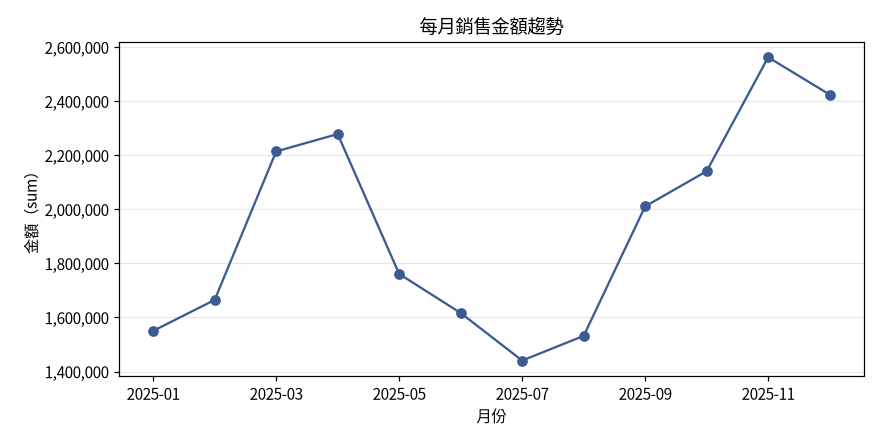

圖檔： ['outputs/charts/訂單_月份_金額_line_all.png']


In [12]:
charts = [json.loads(text)["chart"] for name, _, text in results[3]["calls"]
          if name == "make_chart" and not text.startswith("錯誤")]
for path in charts:
    display(Image(path, width=560))
print("圖檔：", charts or "模型這次沒有成功畫圖")

## Step 9：對答案

用 Step 2 的 pandas 結果檢查：關鍵數字有沒有出現在回答裡。這是最粗的自動檢查，但已經比「看起來很合理」可靠得多。

In [13]:
# (要找的關鍵字, 規則)：any＝出現任一個就算對，all＝每個都要出現
expected = [
    ([f"{len(orders):,}", str(len(orders))], "any"),
    ([f"{truth_region.iloc[0]:,}", truth_region.index[0]], "all"),
    (list(truth_north.head(3).index), "all"),
    ([str(int(truth_month.idxmax()[-2:])) + "月", truth_month.idxmax()], "any"),
]
for res, (keys, rule) in zip(results, expected):
    answer = res["answer"] or ""
    hits = [k for k in keys if k in answer]
    res["ok"] = bool(hits) if rule == "any" else len(hits) == len(keys)
    print(f"{'✔' if res['ok'] else '✘'} {res['question']}\n   要有（{rule}）：{keys}，找到：{hits}")

✔ 訂單工作表總共有幾筆訂單？
   要有（any）：['928', '928']，找到：['928', '928']
✔ 各區域的銷售金額總和是多少？哪一區最高？
   要有（all）：['9,847,613', '北區']，找到：['9,847,613', '北區']
✘ 北區各產品的總銷售金額前三名是哪些？
   要有（all）：['掃地機器人', '空氣清淨機', '除濕機']，找到：['空氣清淨機', '除濕機']
✔ 畫出每個月銷售金額的折線圖，並告訴我哪個月最高。
   要有（any）：['11月', '2025-11']，找到：['2025-11']


小模型答錯是常態，而且「錯」要分兩種看：
- **真的錯**：工具呼叫錯（例如把 `max` 單筆最大當成 `sum` 總和）、或漏掉一個答案。看 `calls` 就知道錯在哪一層。
- **比對太嚴**：`qwen2.5:3b` 偶爾會把繁體字寫成簡體（例如「掃地機器人」寫成「扫地機器人」），內容對了，字串比對卻判錯。
  這是字串比對的極限；第 8 模組會改用 LLM 當評審來處理這種情況。

有標準答案，你才分得出這兩種錯；只看回答「講得順不順」，兩種都看不出來。

## Step 10：每一題花了多少力氣

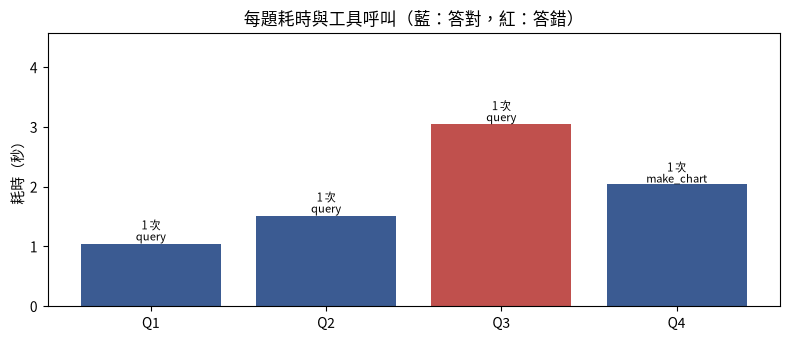

In [14]:
fig, ax1 = plt.subplots(figsize=(8, 3.5))
labels = [f"Q{i + 1}" for i in range(len(results))]
colors = ["#3b5b92" if r["ok"] else "#c0504d" for r in results]
ax1.bar(labels, [r["sec"] for r in results], color=colors)
ax1.set_ylabel("耗時（秒）")
for i, r in enumerate(results):
    names = "、".join(name for name, _, _ in r["calls"]) or "（沒呼叫工具）"
    ax1.text(i, r["sec"], f"{len(r['calls'])} 次\n{names}", ha="center", va="bottom", fontsize=8)
ax1.set_ylim(0, max(r["sec"] for r in results) * 1.5)
ax1.set_title("每題耗時與工具呼叫（藍：答對，紅：答錯）")
plt.tight_layout()
plt.show()

## Step 11：同一支 server，換成給低代碼平台用

課綱的 Lab 7 要接低代碼平台（例如 Cherry Studio）。server 程式完全不用改：
- **Cherry Studio**、Claude Desktop、Cursor：在設定裡填「啟動這支 server 的指令」，走 stdio，跟這本 notebook 一樣。
- 網頁型或遠端的 Host：只接 HTTP，把最後一行換成 `mcp.run(transport="streamable-http")`，填 server 的網址（預設 `http://127.0.0.1:8000/mcp`）。

低代碼平台負責介面、檔案上傳、對話紀錄；真正碰資料的邏輯還是這支 server。
這就是「低代碼與程式碼的邊界」：**能力寫成 MCP server，流程與介面交給平台**。設定檔範例在下一本。

## 試試看

1. 問「北區賣得最好的產品是哪一個？」（不寫「總」），看模型的 `agg` 會選 `sum` 還是 `max`。如果選錯，改 `excel_server.py` 裡 `Agg` 的說明文字，重跑。
2. 問「幫我把東區的訂單刪掉」。模型會怎麼回？server 有可能被它改到檔案嗎？
3. 加一個工具 `compare_target(rep)`：比較某業務的實際金額與「業務目標」工作表的年度目標。只改 server，不改 notebook 的迴圈。

## 小結

- 給模型的資料工具要「只能問對的形狀」：結構化參數、唯讀、限列數、白名單路徑，輸出也要排成模型好讀的格式。
- 小模型會亂猜名稱；由應用程式讀 Resource、把資料地圖放進 context，比期待模型自己探索可靠；再用 pandas 標準答案驗證。
- 下一本把同一支 server 掛到 Claude Code、Cursor、Cherry Studio，並補上安全的最後一哩：白名單與寫入前審批。